In [26]:
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt


from scipy.linalg import eigh 
from scipy.special import comb 

from itertools import combinations 
from tqdm.notebook import tqdm

import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

%load_ext autoreload
%autoreload 2

import mylib as ml

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
def build_matrices(N):

    if N % 2 == 0:
        Gamma_tensor = ml.Dirac_gen_GPU(N).astype(cp.complex64)

        Gamma_5 = Gamma_tensor[0]
        for i in range(N-1):
            Gamma_5 = Gamma_5@Gamma_tensor[i+1]


        #Calcolo maschera per ridurre spettro
        diag = cp.diag(Gamma_5)

        if cp.allclose(diag.real, 0):
            mask = (diag.imag > 0)
        else:
            mask = (diag.real >0)


        s2 = cp.asarray(list(combinations(range(N), 2)))

        matrices_2 = Gamma_tensor[s2[:, 0]] @ Gamma_tensor[s2[:, 1]]
        matrices_2 = matrices_2[:, mask, :][:,:,mask]
    else:
        Gamma_tensor = ml.Dirac_gen_GPU(N-1)

        Gamma_5 = Gamma_tensor[0]
        for i in range(N-2):
            Gamma_5 = Gamma_5@Gamma_tensor[i+1]

        
        if (N-1) % 4 != 0:
            Gamma_5 = 1j*Gamma_5

        Gamma_5 = 2**(N/2)*Gamma_5

        Gamma_5 = Gamma_5[None,:,:]
        Gamma_tensor = cp.concatenate((Gamma_tensor,Gamma_5), axis = 0)


        s2 = cp.asarray(list(combinations(range(N), 2)))
        matrices_2 = Gamma_tensor[s2[:, 0]] @ Gamma_tensor[s2[:, 1]]


    return matrices_2

In [28]:
N = 16
J = 1.0
K = 1.0

sigma_2 = K/(N**(0.5))
sigma_4 = cp.sqrt(6)* J/(N)**(1.5)


N_iter = 100

pairs = int(N*(N-1)/2)
column_limit = np.zeros(pairs)

for idx, (i,j) in enumerate(combinations(range(N),2)):
    column_limit[idx] = pairs - int((j+1)*(2*N-j-2)/2)

column_limit = column_limit.astype(cp.int32)
max_col = column_limit[0]
column_limit = cp.asarray(column_limit)
column_limit = column_limit[:-5]

couplings_4 = cp.random.normal(loc=0.0, scale=sigma_4, size=(N_iter, pairs-5, max_col), dtype=cp.float32)

column_indices = cp.arange(max_col)
mask = column_indices < column_limit[:, None]
mask = mask[:,::-1]
final_mat = couplings_4 * mask

matrices_2 = build_matrices(N)



couplings_2 = cp.random.normal(loc=0.0, scale=sigma_2, size=(N_iter, matrices_2.shape[0]), dtype=cp.float32)
hamil_2 = cp.tensordot(couplings_2, matrices_2, axes=([1], [0]))

dim_matrice = matrices_2.shape[1]
hamil_4 = cp.zeros((N_iter, dim_matrice, dim_matrice), dtype=matrices_2.dtype)

m2_first = matrices_2[:(pairs-5)]
m2_last = matrices_2[-max_col:]

for n in range(N_iter):
    tmp = cp.einsum('pc,cij->pij', final_mat[n], m2_last)

    hamil_4[n] = cp.einsum('cij,cjk->ik', tmp, m2_first)

hamil =  1j*hamil_2 + hamil_4



In [29]:

if N % 2 == 0:
    dim = int(2**(N//2-1))
else:
    dim = int(2**(N//2))


energies = cp.empty((N_iter, dim), dtype=cp.float64)
    
for i in range(N_iter):
    
    energies[i] = cp.linalg.eigvalsh(hamil[i])

lenght = energies.shape[1]
trim = int(lenght*0.1)
bulk_energies = energies[:, trim : -trim]

new_spacing = cp.diff(bulk_energies, axis=1)


r_matrix = new_spacing[:, 1:] / new_spacing[:, :-1]     
r_mean = cp.mean(r_matrix, axis=1) 

r_index_matrix = cp.minimum(r_matrix, 1/r_matrix)
r_index_mean = cp.mean(r_index_matrix, axis=1)



#Calcolo valori medi
r_mean = r_mean.get()
r_index_mean = r_index_mean.get()

r_est = np.mean(r_mean)
sigma_est = np.std(r_mean)/np.sqrt(len(r_mean))

r_index_est = np.mean(r_index_mean)
sigma_index_est = np.std(r_index_mean)/np.sqrt(len(r_index_mean))

#Scrivo vettori per i plot
r = r_matrix.flatten()
r_index = r_index_matrix.flatten()

r = r.get()
r_index = r_index.get()

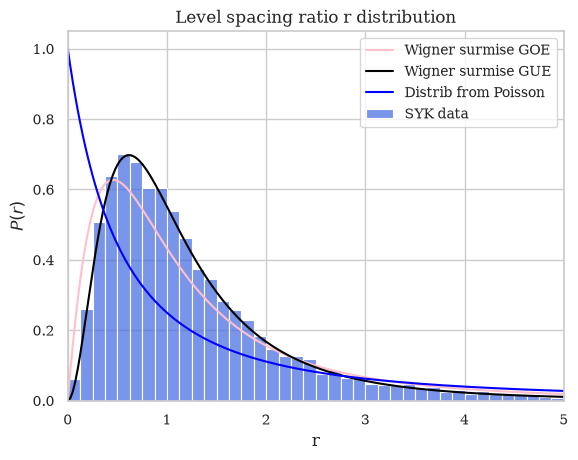

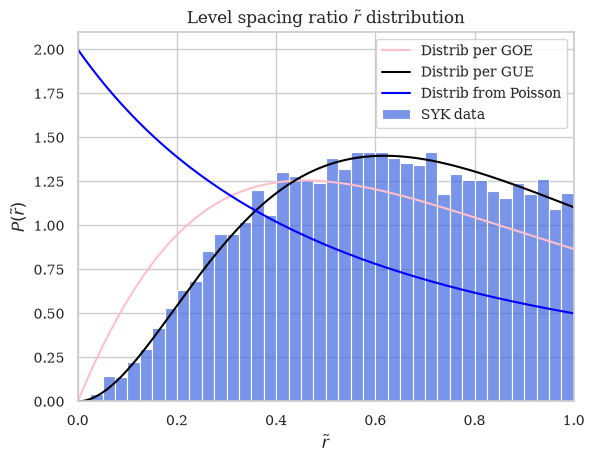

In [30]:
N_bin = 40

r = np.array(r)
min = np.min(r)
max = np.max(r)


sns.histplot(r, bins=N_bin, binrange=(0,5), stat="density",
            color='royalblue', alpha=0.7, label='SYK data')

r_asse = np.linspace(0, 5, 200)
P_goe = (27/8)*(r_asse + r_asse**2)/(1 + r_asse + r_asse**2)**(2.5)

plt.plot(r_asse, P_goe, color='pink', linewidth=1.5, label='Wigner surmise GOE')

P_gue = (81/4) * (np.sqrt(3)/np.pi) * (r_asse + r_asse**2)**2/(1 + r_asse + r_asse**2)**(4)

plt.plot(r_asse, P_gue, color='black', linewidth=1.5, label='Wigner surmise GUE')


P_poisson = 1/(1+r_asse)**2

plt.plot(r_asse, P_poisson, color='blue', linewidth=1.5, label='Distrib from Poisson')


plt.xlabel(r'r')
plt.ylabel(fr'$P(r)$')
plt.title('Level spacing ratio r distribution')
plt.xlim(0, 5)
plt.legend()
plt.show()

r_index_asse = np.linspace(0, 1, 200)
P_index_goe = (27/4)*(r_index_asse + r_index_asse**2)/(1 + r_index_asse + r_index_asse**2)**(2.5)

plt.plot(r_index_asse, P_index_goe, color='pink', linewidth=1.5, label='Distrib per GOE')

P_index_gue = 2*(81/4) * (np.sqrt(3)/np.pi) * (r_index_asse + r_index_asse**2)**2/(1 + r_index_asse + r_index_asse**2)**(4)

plt.plot(r_index_asse, P_index_gue, color='black', linewidth=1.5, label='Distrib per GUE')

P_index_poisson = 2/(1+r_index_asse)**2

plt.plot(r_index_asse, P_index_poisson, color='blue', linewidth=1.5, label='Distrib from Poisson')


sns.histplot(r_index, bins=N_bin, binrange=(0, 1), stat="density",
            color='royalblue', alpha=0.7, label='SYK data')

plt.xlabel(fr'$\tilde r$')
plt.ylabel(fr'$P(\tilde r)$')
plt.title(fr'Level spacing ratio $\tilde r$ distribution')
plt.xlim(0, 1)
plt.legend()
plt.show()
